# Comparison of Scratch and Transfer Learning Baselines

This notebook compares five diabetic retinopathy detection experiments on the same binary APTOS 2019 test split:

- `Custom CNN` trained from scratch
- `Baseline ResNet18` with pretrained weights
- `Preprocessed ResNet18` with pretrained weights and retinal preprocessing
- `DenseNet121` with pretrained weights
- `EfficientNet-B0` with pretrained weights

The goal is to benchmark scratch learning against several transfer learning baselines and to analyze the trade-off between overall performance and clinically important error types.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import torch
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score, roc_curve
from torch.utils.data import DataLoader

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)


In [2]:
project_root = Path.cwd().resolve()
for candidate in [project_root, *project_root.parents]:
    if (candidate / "src").exists() and (candidate / "configs").exists():
        project_root = candidate
        break

sys.path.insert(0, str(project_root / "src"))

from dr_detection.config import load_yaml_config, resolve_path
from dr_detection.dataset import FundusImageDataset, default_transforms, load_fundus_records
from dr_detection.train import build_model

comparison_dir = project_root / "outputs" / "comparison_all"
comparison_dir.mkdir(parents=True, exist_ok=True)

model_specs = [
    {
        "display_name": "Custom CNN (Scratch)",
        "short_name": "custom_cnn",
        "column_name": "Custom CNN",
        "config_path": project_root / "configs" / "custom_cnn_scratch.yaml",
    },
    {
        "display_name": "Baseline ResNet18",
        "short_name": "resnet18_baseline",
        "column_name": "ResNet18",
        "config_path": project_root / "configs" / "default.yaml",
    },
    {
        "display_name": "ResNet18 + Preprocessing",
        "short_name": "resnet18_preprocessed",
        "column_name": "ResNet18 + Preprocessing",
        "config_path": project_root / "configs" / "resnet18_preprocessed.yaml",
    },
    {
        "display_name": "DenseNet121",
        "short_name": "densenet121_baseline",
        "column_name": "DenseNet121",
        "config_path": project_root / "configs" / "densenet121_baseline.yaml",
    },
    {
        "display_name": "EfficientNet-B0",
        "short_name": "efficientnet_b0_baseline",
        "column_name": "EfficientNet-B0",
        "config_path": project_root / "configs" / "efficientnet_b0_baseline.yaml",
    },
]

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"Comparison output directory: {comparison_dir}")
print(f"Device: {device}")


Comparison output directory: /Users/berekebaimuratov/Desktop/Detection of Diabetic Retinopathy/outputs/comparison_all
Device: mps


In [3]:
def evaluate_model(spec: dict) -> tuple[dict, pd.DataFrame, dict]:
    config = load_yaml_config(spec["config_path"])
    dataset_cfg = config["dataset"]
    training_cfg = config["training"]
    checkpoint_path = resolve_path(project_root, config["paths"]["model_dir"]) / "best_model.pt"

    test_records = load_fundus_records(
        csv_path=resolve_path(project_root, dataset_cfg["test_csv_path"]),
        images_dir=resolve_path(project_root, dataset_cfg["test_images_dir"]),
        image_extension=dataset_cfg.get("image_extension", ".png"),
        binary_classification=dataset_cfg.get("binary_classification", True),
    )

    test_dataset = FundusImageDataset(
        test_records,
        transform=default_transforms(
            image_size=dataset_cfg.get("image_size", 224),
            train=False,
            preprocessing_cfg=dataset_cfg.get("preprocessing"),
        ),
    )
    test_loader = DataLoader(
        test_dataset,
        batch_size=training_cfg.get("batch_size", 16),
        shuffle=False,
        num_workers=0,
    )

    checkpoint = torch.load(checkpoint_path, map_location=device)
    model = build_model(
        model_name=checkpoint["model_name"],
        num_classes=checkpoint["num_classes"],
        pretrained=False,
    )
    model.load_state_dict(checkpoint["model_state_dict"])
    model = model.to(device)
    model.eval()

    labels = []
    predictions = []
    scores = []
    image_paths = []

    with torch.no_grad():
        for images, batch_labels, batch_paths in test_loader:
            images = images.to(device)
            logits = model(images)
            probabilities = torch.softmax(logits, dim=1)
            batch_predictions = probabilities.argmax(dim=1)

            labels.extend(batch_labels.tolist())
            predictions.extend(batch_predictions.cpu().tolist())
            scores.extend(probabilities[:, 1].cpu().tolist())
            image_paths.extend(batch_paths)

    cm = confusion_matrix(labels, predictions)
    tn, fp, fn, tp = cm.ravel()

    metrics = {
        "model": spec["display_name"],
        "accuracy": accuracy_score(labels, predictions),
        "precision": precision_score(labels, predictions, zero_division=0),
        "recall": recall_score(labels, predictions, zero_division=0),
        "f1_score": f1_score(labels, predictions, zero_division=0),
        "roc_auc": roc_auc_score(labels, scores),
        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp),
    }

    predictions_df = pd.DataFrame(
        {
            "image_path": image_paths,
            "true_label": labels,
            "predicted_label": predictions,
            "positive_score": scores,
        }
    )

    fpr, tpr, _ = roc_curve(labels, scores)
    roc_data = {
        "fpr": fpr,
        "tpr": tpr,
        "roc_auc": metrics["roc_auc"],
    }

    return metrics, predictions_df, roc_data


In [4]:
results = {}
for spec in model_specs:
    metrics, predictions_df, roc_data = evaluate_model(spec)
    results[spec["short_name"]] = {
        "metrics": metrics,
        "predictions": predictions_df,
        "roc": roc_data,
    }

metrics_overview_df = pd.DataFrame([
    results[spec["short_name"]]["metrics"] for spec in model_specs
])
metrics_overview_df[["accuracy", "precision", "recall", "f1_score", "roc_auc"]] = metrics_overview_df[["accuracy", "precision", "recall", "f1_score", "roc_auc"]].round(4)
metrics_overview_df


,model,accuracy,precision,recall,f1_score,roc_auc,true_negative,false_positive,false_negative,true_positive
0,Custom CNN (Scratch),0.9426,0.9740,0.8982,0.9346,0.9757,195,4,17,150
1,Baseline ResNet18,0.9781,0.9649,0.9880,0.9763,0.9974,193,6,2,165
2,ResNet18 + Preprocessing,0.9809,0.9819,0.9760,0.9790,0.9971,196,3,4,163
3,DenseNet121,0.9672,0.9697,0.9581,0.9639,0.9932,194,5,7,160
4,EfficientNet-B0,0.9891,0.9939,0.9820,0.9880,0.9983,198,1,3,164


**Table 6.1. Final test-set metric comparison across all scratch and transfer learning baselines**


In [5]:
metric_names = ["accuracy", "precision", "recall", "f1_score", "roc_auc"]
metrics_comparison_df = pd.DataFrame({"metric": metric_names})
for spec in model_specs:
    metrics_comparison_df[spec["column_name"]] = [
        results[spec["short_name"]]["metrics"][metric] for metric in metric_names
    ]

metric_columns = [spec["column_name"] for spec in model_specs]
metrics_comparison_df[metric_columns] = metrics_comparison_df[metric_columns].round(4)
metrics_comparison_df.to_csv(comparison_dir / "table_6_1_all_model_metrics.csv", index=False)
metrics_comparison_df


,metric,Custom CNN,ResNet18,ResNet18 + Preprocessing,DenseNet121,EfficientNet-B0
0,accuracy,0.9426,0.9781,0.9809,0.9672,0.9891
1,precision,0.9740,0.9649,0.9819,0.9697,0.9939
2,recall,0.8982,0.9880,0.9760,0.9581,0.9820
3,f1_score,0.9346,0.9763,0.9790,0.9639,0.9880
4,roc_auc,0.9757,0.9974,0.9971,0.9932,0.9983


**Table 6.2. Confusion-matrix count comparison across all scratch and transfer learning baselines**


In [6]:
outcome_rows = [
    ("True Negative", "true_negative"),
    ("False Positive", "false_positive"),
    ("False Negative", "false_negative"),
    ("True Positive", "true_positive"),
]
confusion_comparison_df = pd.DataFrame({"outcome": [label for label, _ in outcome_rows]})
for spec in model_specs:
    confusion_comparison_df[spec["column_name"]] = [
        results[spec["short_name"]]["metrics"][key] for _, key in outcome_rows
    ]

confusion_comparison_df.to_csv(comparison_dir / "table_6_2_all_model_confusion_counts.csv", index=False)
confusion_comparison_df


,outcome,Custom CNN,ResNet18,ResNet18 + Preprocessing,DenseNet121,EfficientNet-B0
0,True Negative,195,193,196,194,198
1,False Positive,4,6,3,5,1
2,False Negative,17,2,4,7,3
3,True Positive,150,165,163,160,164


**Table 6.3. Recall-focused clinical comparison across all baseline models**


In [7]:
clinical_summary_df = metrics_overview_df[[
    "model",
    "recall",
    "precision",
    "f1_score",
    "false_negative",
    "false_positive",
]].copy()
clinical_summary_df = clinical_summary_df.sort_values(by=["recall", "f1_score"], ascending=[False, False]).reset_index(drop=True)
clinical_summary_df[["recall", "precision", "f1_score"]] = clinical_summary_df[["recall", "precision", "f1_score"]].round(4)
clinical_summary_df.to_csv(comparison_dir / "table_6_3_clinical_summary.csv", index=False)
clinical_summary_df


,model,recall,precision,f1_score,false_negative,false_positive
0,Baseline ResNet18,0.9880,0.9649,0.9763,2,6
1,EfficientNet-B0,0.9820,0.9939,0.9880,3,1
2,ResNet18 + Preprocessing,0.9760,0.9819,0.9790,4,3
3,DenseNet121,0.9581,0.9697,0.9639,7,5
4,Custom CNN (Scratch),0.8982,0.9740,0.9346,17,4


**Figure 6.1. Test-set metric comparison across all scratch and transfer learning baselines**


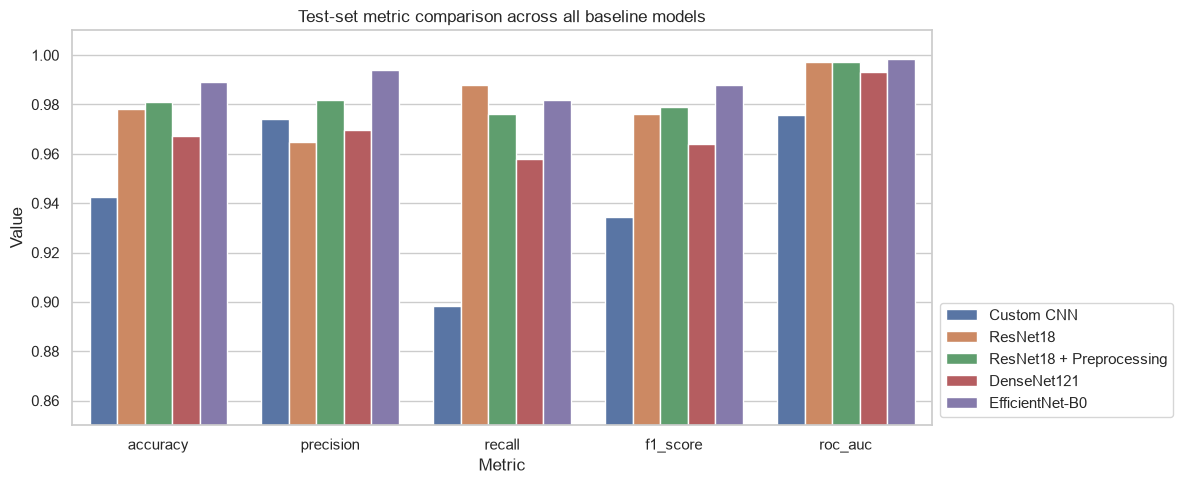

In [8]:
plot_df = metrics_comparison_df.melt(
    id_vars="metric",
    value_vars=[spec["column_name"] for spec in model_specs],
    var_name="model",
    value_name="value",
)

fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=plot_df, x="metric", y="value", hue="model", ax=ax)
ax.set_title("Test-set metric comparison across all baseline models")
ax.set_xlabel("Metric")
ax.set_ylabel("Value")
ax.set_ylim(0.85, 1.01)
ax.legend(loc="lower left", bbox_to_anchor=(1.01, 0.02), borderaxespad=0)
plt.tight_layout()
fig.savefig(comparison_dir / "figure_6_1_all_model_metric_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


**Figure 6.2. False-positive and false-negative comparison across all baseline models**


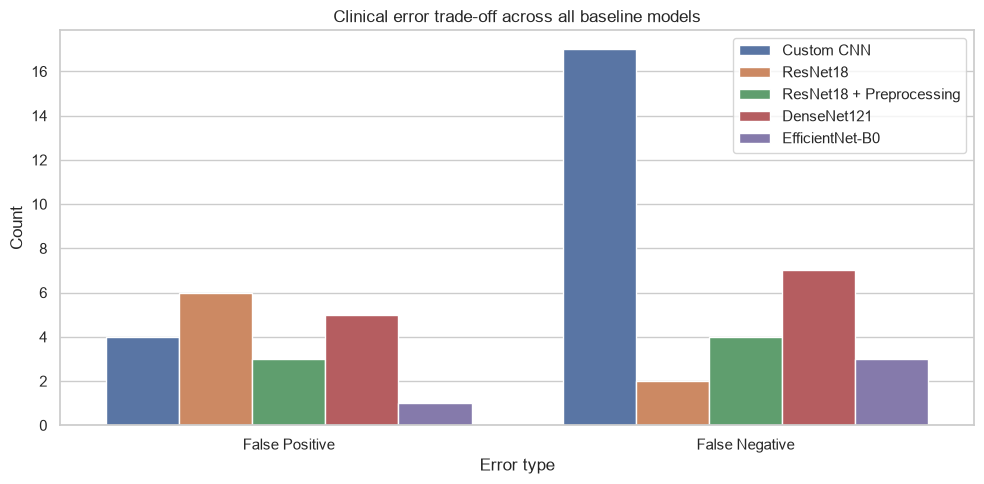

In [9]:
error_tradeoff_df = confusion_comparison_df.loc[
    confusion_comparison_df["outcome"].isin(["False Positive", "False Negative"])
].melt(
    id_vars="outcome",
    value_vars=[spec["column_name"] for spec in model_specs],
    var_name="model",
    value_name="count",
)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=error_tradeoff_df, x="outcome", y="count", hue="model", ax=ax)
ax.set_title("Clinical error trade-off across all baseline models")
ax.set_xlabel("Error type")
ax.set_ylabel("Count")
ax.legend(loc="upper right")
plt.tight_layout()
fig.savefig(comparison_dir / "figure_6_2_all_model_error_tradeoff.png", dpi=300, bbox_inches="tight")
plt.show()


**Figure 6.3. ROC-curve comparison across all scratch and transfer learning baselines**


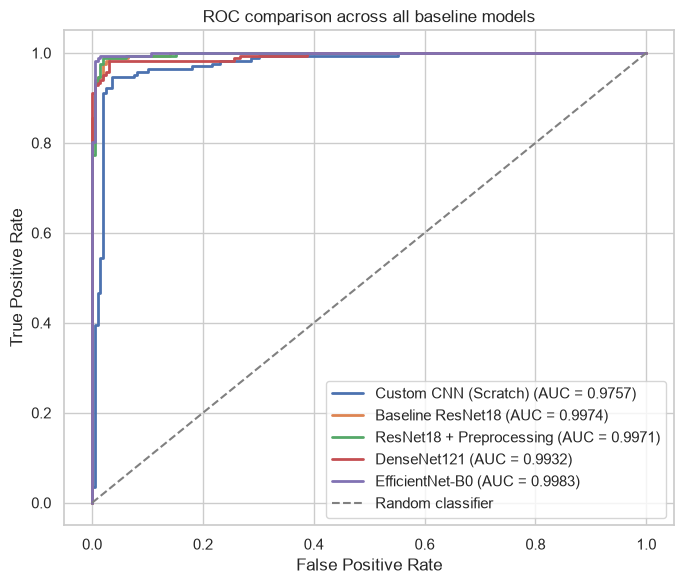

In [10]:
fig, ax = plt.subplots(figsize=(7, 6))
for spec in model_specs:
    roc_data = results[spec["short_name"]]["roc"]
    ax.plot(
        roc_data["fpr"],
        roc_data["tpr"],
        linewidth=2,
        label=f"{spec['display_name']} (AUC = {roc_data['roc_auc']:.4f})",
    )

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random classifier")
ax.set_title("ROC comparison across all baseline models")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(loc="lower right")
plt.tight_layout()
fig.savefig(comparison_dir / "figure_6_3_all_model_roc_curves.png", dpi=300, bbox_inches="tight")
plt.show()
